# 1.0 Raw inventory and annotation checks (RoundaboutHD)
Goal: understand every annotation file, its format, and what is broken, before preparing training data.
Data: `data/raw/RoundaboutHD/` (pulled via DVC, videos excluded).

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # repo root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.load import RAW, CAMS, load_sct, load_mcam, load_det_zip
pd.set_option("display.width", 160)
IMG_W, IMG_H = 3840, 2160  # 4K, assumption checked below via max coordinates

## 1. Inventory: README vs. actual files

In [2]:
documented = ["layout.jpg", "vehicle_statistic.xlsx", "Multi_CAM_Ground_Truth.txt", "ReID_subset/ReID_subset.zip",
              "imagesc001/SCT/imagesc001_SCT_GT.txt", "imagesc001/detection/labels_GT.zip",
              "imagesc001/detection/labels_test.zip", "imagesc001/detection/labels_xy.zip",
              "imagesc001/geo-mapping/cam01_fitted_cam.json", "imagesc001/geo-mapping/cam01_info.png",
              "imagesc001/geo-mapping/cam01_topview.jpg", "imagesc001/geo-mapping/cam01_trace.png",
              "imagesc001/geo-mapping/cam01_undistorted.png", "imagesc001/video.mp4"]
pd.DataFrame({"documented": documented, "exists": [(RAW / p).exists() for p in documented]})

,documented,exists
0,layout.jpg,True
1,vehicle_statistic.xlsx,True
2,Multi_CAM_Ground_Truth.txt,False
3,ReID_subset/ReID_subset.zip,False
4,imagesc001/SCT/imagesc001_SCT_GT.txt,False
5,imagesc001/detection/labels_GT.zip,True
6,imagesc001/detection/labels_test.zip,True
7,imagesc001/detection/labels_xy.zip,True
8,imagesc001/geo-mapping/cam01_fitted_cam.json,True
9,imagesc001/geo-mapping/cam01_info.png,True


In [3]:
# what actually exists (excluding the ReID crops)
actual = sorted(str(p.relative_to(RAW)) for p in RAW.rglob("*")
                if p.is_file() and "Reid_subset" not in str(p) and not p.name.startswith("."))
actual

['Multi_CAM_Ground_Turth.txt',
 'README.md',
 'Vehicle_statistic.xlsx',
 'imagesc001/SCT/SCT_GT.txt',
 'imagesc001/detection/labels_GT.zip',
 'imagesc001/detection/labels_test.zip',
 'imagesc001/detection/labels_xy.zip',
 'imagesc001/geo-mapping/cam01.yaml',
 'imagesc001/geo-mapping/cam01_fitted_cam.json',
 'imagesc001/geo-mapping/cam01_info.png',
 'imagesc001/geo-mapping/cam01_topview.jpg',
 'imagesc001/geo-mapping/cam01_trace.png',
 'imagesc002/SCT/SCT_GT.txt',
 'imagesc002/detection/labels_GT.zip',
 'imagesc002/detection/labels_test.zip',
 'imagesc002/detection/labels_xy.zip',
 'imagesc002/geo-mapping/cam02.yaml',
 'imagesc002/geo-mapping/cam02_fitted_cam.json',
 'imagesc002/geo-mapping/cam02_info.png',
 'imagesc002/geo-mapping/cam02_topview.jpg',
 'imagesc002/geo-mapping/cam02_trace.png',
 'imagesc003/SCT/SCT_GT.txt',
 'imagesc003/detection/labels_GT.zip',
 'imagesc003/detection/labels_test.zip',
 'imagesc003/detection/labels_xy.zip',
 'imagesc003/geo-mapping/cam03.yaml',
 'imagesc

## 2. Single-camera tracking GT (`imagesc00x/SCT/SCT_GT.txt`)
README format: `frame track_id bb0 bb1 bb2 bb3 cls`, box format not stated.

In [4]:
sct = load_sct()
print(len(sct), "rows"); sct.head()

232945 rows


,frame,track_id,a,b,c,d,cls,cam
0,1,1,299.00,1118.00,887.00,1562.00,2,1
1,2,1,352.80,1086.76,932.99,1510.80,2,1
2,3,1,409.82,1057.61,980.05,1465.55,2,1
3,4,1,469.57,1025.30,1031.48,1414.75,2,1
4,5,1,528.16,991.50,1081.07,1369.94,2,1


In [5]:
# Box format: if c>a and d>b on every row it is x1 y1 x2 y2 (with w,h, c<a would occur for boxes on the right side)
print("c>a:", (sct.c > sct.a).mean(), " d>b:", (sct.d > sct.b).mean())
print("as x1y1x2y2 -> max x2, y2:", sct.c.max(), sct.d.max(), "| as x1y1wh -> max x1+w:", (sct.a + sct.c).max())

c>a: 1.0  d>b: 1.0
as x1y1x2y2 -> max x2, y2: 3851.08 2160.75 | as x1y1wh -> max x1+w: 7663.42


In [6]:
sct = sct.rename(columns={"a": "x1", "b": "y1", "c": "x2", "d": "y2"})
sct["w"], sct["h"] = sct.x2 - sct.x1, sct.y2 - sct.y1
out = (sct.x1 < 0) | (sct.y1 < 0) | (sct.x2 > IMG_W) | (sct.y2 > IMG_H)
print("boxes outside 3840x2160:", out.sum(), f"({out.mean():.2%})")
print("max overshoot px: x", (sct.x2 - IMG_W).max().round(2), " y", (sct.y2 - IMG_H).max().round(2))
print("non-positive w/h:", ((sct.w <= 0) | (sct.h <= 0)).sum())
sct[["w", "h"]].describe().round(1)

boxes outside 3840x2160: 748 (0.32%)
max overshoot px: x 11.08  y 0.75
non-positive w/h: 0


,w,h
count,232945.0,232945.0
mean,173.5,112.7
std,174.0,118.9
min,15.2,18.9
25%,72.6,48.4
50%,122.6,71.5
75%,189.2,128.1
max,2194.2,1750.4


In [7]:
print("classes:", sct.cls.value_counts().to_dict())
print(sct.groupby("cam").frame.agg(["min", "max", "nunique"]))
print("duplicate (cam, frame, track_id):", sct.duplicated(["cam", "frame", "track_id"]).sum())

classes: {2: 232945}
     min   max  nunique
cam                    
1      1  9000     9000
2      1  9000     8999
3      1  9000     9000
4      1  9000     8869
duplicate (cam, frame, track_id): 26


tracks per cam: {1: 262, 2: 244, 3: 279, 4: 257}
track ids shared between cameras: 33
tracks with gaps: 7  | very short tracks (<10 frames): 0


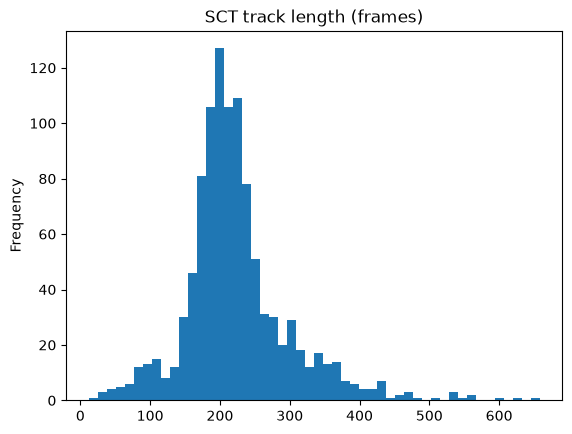

In [8]:
# tracks: length, fragmentation (gaps in frame sequence)
g = sct.groupby(["cam", "track_id"]).frame
tracks = pd.DataFrame({"n": g.size(), "first": g.min(), "last": g.max()})
tracks["gaps"] = tracks["last"] - tracks["first"] + 1 - tracks["n"]
print("tracks per cam:", tracks.groupby("cam").size().to_dict())
print("track ids shared between cameras:", len(set.intersection(*[set(tracks.loc[c].index) for c in CAMS])))
print("tracks with gaps:", (tracks.gaps > 0).sum(), " | very short tracks (<10 frames):", (tracks.n < 10).sum())
tracks.n.plot.hist(bins=50, title="SCT track length (frames)"); plt.show()

## 3. Multi-camera GT (`Multi_CAM_Ground_Turth.txt`)
README format: `cam id frame x1 y1 w h xworld yworld`.

In [9]:
mcam = load_mcam()
print(len(mcam), "rows"); mcam.head()

177782 rows


,cam,id,frame,x1,y1,w,h,xworld,yworld
0,1,645,123,2310.00,89.00,39.00,27.00,-1,-1
1,1,645,124,2310.80,88.20,36.60,28.60,-1,-1
2,1,645,125,2310.17,87.29,36.13,31.17,-1,-1
3,1,645,126,2308.39,89.18,35.98,29.14,-1,-1
4,1,645,127,2305.60,90.66,38.22,29.04,-1,-1


In [10]:
print("world coords == -1:", f"{(mcam.xworld == -1).mean():.1%}", "| y:", f"{(mcam.yworld == -1).mean():.1%}")
print("non-positive w/h:", ((mcam.w <= 0) | (mcam.h <= 0)).sum())
print("outside image:", ((mcam.x1 + mcam.w > IMG_W) | (mcam.y1 + mcam.h > IMG_H) | (mcam.x1 < 0) | (mcam.y1 < 0)).sum())
print("duplicate (cam, frame, id):", mcam.duplicated(["cam", "frame", "id"]).sum())
print(mcam.groupby("cam").frame.agg(["min", "max"]).T)

world coords == -1: 100.0% | y: 100.0%
non-positive w/h: 0
outside image: 673
duplicate (cam, frame, id): 26
cam     1     2     3     4
min   123     1     1     1
max  9000  9000  9000  8966


In [11]:
cams_per_id = mcam.groupby("id").cam.nunique()
print("global ids:", cams_per_id.size, "| id range:", mcam.id.min(), "-", mcam.id.max())
print("cameras per id:", cams_per_id.value_counts().sort_index().to_dict())
print("ids seen in only 1 camera:", sorted(cams_per_id[cams_per_id == 1].index))

global ids: 311 | id range: 2 - 744
cameras per id: {1: 6, 2: 162, 3: 69, 4: 74}
ids seen in only 1 camera: [72, 78, 87, 129, 182, 354]


### Link SCT track_id ↔ Multi-CAM id
Match boxes in the same (cam, frame) by IoU. If both files describe the same vehicles, each SCT track should map to
exactly one global id.

In [12]:
def iou(a, b):
    ix = (np.minimum(a[:, 2], b[:, 2]) - np.maximum(a[:, 0], b[:, 0])).clip(0)
    iy = (np.minimum(a[:, 3], b[:, 3]) - np.maximum(a[:, 1], b[:, 1])).clip(0)
    inter = ix * iy
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a) + area(b) - inter)

mc = mcam.assign(mx1=mcam.x1, my1=mcam.y1, mx2=mcam.x1 + mcam.w, my2=mcam.y1 + mcam.h)[["cam", "frame", "id", "mx1", "my1", "mx2", "my2"]]
j = sct.merge(mc, on=["cam", "frame"])
j["iou"] = iou(j[["x1", "y1", "x2", "y2"]].values, j[["mx1", "my1", "mx2", "my2"]].values)
best = j.sort_values("iou").drop_duplicates(["cam", "frame", "track_id"], keep="last")
print("IoU of best match:", best.iou.describe().round(3).to_dict())
link = best[best.iou > 0.9]
print(f"Multi-CAM rows matched to an SCT box (IoU>0.9): {len(link)}/{len(mcam)}")
print("SCT track_id == Multi-CAM id:", f"{(link.track_id == link.id).mean():.1%}")

IoU of best match: {'count': 231435.0, 'mean': 0.769, 'std': 0.42, 'min': 0.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 1.0}
Multi-CAM rows matched to an SCT box (IoU>0.9): 177704/177782
SCT track_id == Multi-CAM id: 0.0%


In [13]:
# is the mapping consistent per track?
m = link.groupby(["cam", "track_id"]).id.agg(["nunique", lambda s: s.mode()[0]])
m.columns = ["n_ids", "id"]
print("SCT tracks linked to a global id:", len(m), "of", len(tracks))
print("tracks mapped to >1 global id:", (m.n_ids > 1).sum())
print("global ids built from >1 track in the same cam:", m.groupby(["cam", "id"]).size().gt(1).sum())

SCT tracks linked to a global id: 834 of 1042
tracks mapped to >1 global id: 2
global ids built from >1 track in the same cam: 2


## 4. Detection labels (`imagesc00x/detection/*.zip`)
Three sets per camera. Read from the zip directly; frame index from the file name `imgNNNNNN.txt`.

In [14]:
det = {k: pd.concat([load_det_zip(c, k) for c in CAMS], ignore_index=True) for k in ["GT", "test", "xy"]}
for k, d in det.items():
    print(f"{k:5s} rows={len(d):7d} cols={d.shape[1]-2} frames={d.frame.min()}-{d.frame.max()} classes={d.v0.value_counts().to_dict()}")
det["GT"].head()

GT    rows= 574607 cols=6 frames=0-8999 classes={2.0: 499116, 7.0: 75258, 5.0: 226, 3.0: 7}
test  rows= 233224 cols=6 frames=0-8999 classes={2.0: 233224}
xy    rows= 648928 cols=6 frames=0-8999 classes={2.0: 570904, 7.0: 77770, 5.0: 245, 3.0: 9}


,frame,v0,v1,v2,v3,v4,v5,cam
0,5,2.0,591.0,960.0,1132.0,1317.0,0.95,1
1,5,2.0,3646.0,838.0,3839.0,996.0,0.93,1
2,5,2.0,3456.0,638.0,3773.0,773.0,0.90,1
3,5,2.0,3558.0,752.0,3839.0,881.0,0.88,1
4,5,2.0,1064.0,265.0,1226.0,343.0,0.82,1


In [15]:
# Which frame offset aligns detection labels with SCT? (SCT is 1-based; det file names start at 0)
# Use labels_test (README: SCT-based) - labels_GT also contains parked cars/trucks that are not in SCT.
cols = {"v0": "cls", "v1": "x1", "v2": "y1", "v3": "x2", "v4": "y2", "v5": "conf"}
dgt, dtest = det["GT"].rename(columns=cols), det["test"].rename(columns=cols)
sample = dtest[dtest.frame % 10 == 5]
for off in [-1, 0, 1]:
    jj = sample.assign(frame=sample.frame + off).merge(sct, on=["cam", "frame"], suffixes=("", "_s"))
    jj["iou"] = iou(jj[["x1", "y1", "x2", "y2"]].values, jj[["x1_s", "y1_s", "x2_s", "y2_s"]].values)
    print(f"offset {off:+d}: share of det boxes with an SCT box IoU>0.9 = {(jj.groupby(['cam','frame','x1','y1']).iou.max() > 0.9).mean():.1%}")

offset -1: share of det boxes with an SCT box IoU>0.9 = 6.6%
offset +0: share of det boxes with an SCT box IoU>0.9 = 22.7%
offset +1: share of det boxes with an SCT box IoU>0.9 = 99.1%


In [16]:
print("labels_test conf values:", dtest.conf.unique())
print("boxes per frame: SCT", sct.groupby(["cam", "frame"]).size().mean().round(1), "| labels_GT", dgt.groupby(["cam", "frame"]).size().mean().round(1))
print("labels_GT conf values:", dgt.conf.describe().round(3).to_dict())
print("boxes per frame (GT):", dgt.groupby(["cam", "frame"]).size().describe().round(1).to_dict())
print("boxes outside image (GT):", ((dgt.x2 > IMG_W) | (dgt.y2 > IMG_H) | (dgt.x1 < 0) | (dgt.y1 < 0)).sum())
print("frames without a label file entry (GT):", 4 * 9000 - dgt.groupby(["cam", "frame"]).ngroups)

labels_test conf values: [1.]
boxes per frame: SCT 6.5 | labels_GT 16.0
labels_GT conf values: {'count': 574607.0, 'mean': 0.646, 'std': 0.187, 'min': 0.3, '25%': 0.477, '50%': 0.66, '75%': 0.82, 'max': 1.0}
boxes per frame (GT): {'count': 36000.0, 'mean': 16.0, 'std': 4.5, 'min': 2.0, '25%': 13.0, '50%': 16.0, '75%': 19.0, 'max': 29.0}
boxes outside image (GT): 0
frames without a label file entry (GT): 0


## 5. Vehicle statistics (`Vehicle_statistic.xlsx`)

In [17]:
xl = pd.read_excel(RAW / "Vehicle_statistic.xlsx", sheet_name=None)
for name, df in xl.items():
    print(f"--- sheet '{name}': {df.shape}"); display(df.head())

--- sheet 'imagesc001': (262, 10)


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,Unnamed: 7,Unnamed: 8,SUV and Offroaders
0,1,Dark Blue,Hyundai,Sonata,NaN,Small Passenger Vehicles,NaN,NaN,NaN,People Carriers and MPV
1,5,White,Toyota,Camry,NaN,Small Passenger Vehicles,NaN,NaN,NaN,Pick Up
2,13,Black,Chevrolet,Malibu,NaN,Small Passenger Vehicles,NaN,NaN,NaN,Commercial Van
3,14,Silver,Toyota,RAV4,NaN,SUV and Offroaders,NaN,NaN,NaN,Heavy Duty Trucks
4,15,Green,Peterbilt,Vehicle Transporter,NaN,Heavy Duty Trucks,NaN,NaN,NaN,Small Passenger Vehicles


--- sheet 'imagesc002': (244, 8)


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,SUV and Offroaders
0,1,Grey,Dodge,Ram,NaN,Pick Up,NaN,People Carriers and MPV
1,2,Red,Concrete,Mixer,NaN,Heavy Duty Trucks,NaN,Pick Up
2,3,White,Chevrolet,Silverado,NaN,Pick Up,NaN,Commercial Van
3,4,White,Ford,Transit,NaN,Commercial Van,NaN,Heavy Duty Trucks
4,10,Silver,Tesla,Model 3,NaN,Small Passenger Vehicles,NaN,Small Passenger Vehicles


--- sheet 'imagesc003': (279, 8)


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,Unnamed: 7
0,1,White Blue Black,Honda,CRV,NaN,SUV and Offroaders,NaN,SUV and Offroaders
1,2,Grey,Toyota,Highlander,NaN,SUV and Offroaders,NaN,People Carriers and MPV
2,3,Black,Toyota,Highlander,NaN,SUV and Offroaders,NaN,Pick Up
3,7,NaN,NaN,NaN,NaN,Small Passenger Vehicles,NaN,NaN
4,11,Silver,Subaru,Outback,NaN,SUV and Offroaders,NaN,Commercial Van


--- sheet 'imagesc004': (257, 32)


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,1,White,Ford,F150,NaN,Pick Up,NaN,SUV and Offroaders,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Black,Cadillac,Escalade,NaN,SUV and Offroaders,NaN,People Carriers and MPV,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Dark Red,Dodge,RAM,NaN,Pick Up,NaN,Pick Up,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5,Black,Nissan,Maxima,NaN,Small Passenger Vehicles,NaN,Commercial Van,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7,Silver,Chrysler,Pacifica,NaN,People Carriers and MPV,NaN,Heavy Duty Trucks,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
# Is 'Number' the per-camera SCT track_id? Only the first 6 columns are data; the rest is a category legend / junk.
for c in CAMS:
    df = xl[f"imagesc{c:03d}"].iloc[:, :6]
    ids = set(tracks.loc[c].index)
    print(f"cam{c}: rows={len(df)} Number==SCT ids: {set(df.Number) == ids} | dup Number={df.Number.duplicated().sum()} "
          f"| missing Make/Model={df[['Make','Model']].isna().any(axis=1).sum()} | categories={df.Category.nunique()}")
print(pd.concat([xl[f"imagesc{c:03d}"].iloc[:, :6] for c in CAMS]).Category.value_counts())

cam1: rows=262 Number==SCT ids: True | dup Number=0 | missing Make/Model=0 | categories=6
cam2: rows=244 Number==SCT ids: True | dup Number=0 | missing Make/Model=1 | categories=6
cam3: rows=279 Number==SCT ids: True | dup Number=0 | missing Make/Model=2 | categories=6
cam4: rows=257 Number==SCT ids: True | dup Number=0 | missing Make/Model=0 | categories=6
Category
SUV and Offroaders          475
Small Passenger Vehicles    288
Pick Up                     114
Heavy Duty Trucks            56
Commercial Van               55
People Carriers and MPV      53
Name: count, dtype: int64


## 6. Findings

**Files / README**
- File names differ from README: `Multi_CAM_Ground_Turth.txt` (typo), `Vehicle_statistic.xlsx`, `SCT/SCT_GT.txt`,
  ReID subset is already unzipped as `RoundaboutHD_Reid_subset/`. `camXX_undistorted.png` is missing, `camXX.yaml` is undocumented
  (config of the camera-fitting script, contains an absolute path from the authors' machine).
- Inside the detection zips the folder names differ: `labels_filtered/` (GT), `labels_sct2det/` (test), `labels_xy/` (xy).

**SCT GT**
- Box format is **x1 y1 x2 y2** in pixels (not x1 y1 w h). Frames are 1-based (1..9000).
- `track_id` is **local per camera** (ids 1, 2, ... repeat across cameras) → not a cross-camera ID.
- `cls` is always 2 (car), although trucks/buses are in the scene → use the xlsx `Category` instead.
- 0.32% of boxes exceed the 3840×2160 frame by ≤ 11 px → clip. 26 duplicate (cam, frame, track_id) rows.

**Multi-CAM GT**
- `id` is the **global (cross-camera) ID**; 311 vehicles, 6 of them seen in only one camera.
- **World coordinates are missing: `xworld/yworld = -1` on 100% of rows.** Would need to be computed from geo-mapping if needed.
- Same boxes as SCT (IoU 1.0) but only for 834 of 1042 SCT tracks (vehicles that are matched across cameras).
  2 SCT tracks map to more than one global id, 2 global ids merge two tracks of the same camera → small ID errors to check visually.
- Same 26 duplicate rows as SCT.

**Detection labels**
- Detection file `imgN.txt` = SCT frame **N+1** (0-based vs 1-based) → off-by-one trap when extracting frames.
- Format per row: `cls x1 y1 x2 y2 conf` in pixels (COCO class ids: 2 car, 7 truck, 5 bus, 3 motorcycle). Needs conversion for YOLO (normalised cx cy w h).
- `labels_GT` (~16 boxes/frame) includes parked cars and still carries detector confidences (0.3–1.0) → looks like *filtered and
  corrected YOLO output*, not drawn from scratch. `labels_test` = SCT boxes (conf 1, class 2 only). `labels_xy` = raw YOLOv12x.

**Vehicle statistics**
- One sheet per camera, keyed by the per-camera SCT `track_id` (`Number`). Only the first 6 columns are data; extra columns are a
  category legend / empty. Some rows have no make/model.